<a href="https://colab.research.google.com/github/Simpson69-il/DEEPLEARNING5THSEM/blob/main/EXPERIMENT%208/Experiment_7_Autoencoder.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 7: Simple Autoencoder for Dimensionality Reduction and Feature Learning

**Aim:** Train an Autoencoder on MNIST, compress each 28×28 image into a lower-dimensional latent representation, reconstruct the image, and evaluate reconstruction quality.

**Dataset:** MNIST handwritten digits (loaded directly through Keras).



In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))

TensorFlow version: 2.21.0
GPU available: False


## Part A – Dataset preparation

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training shape: (60000, 28, 28)
Testing shape: (10000, 28, 28)
Data type: uint8
Original pixel range: 0 to 255


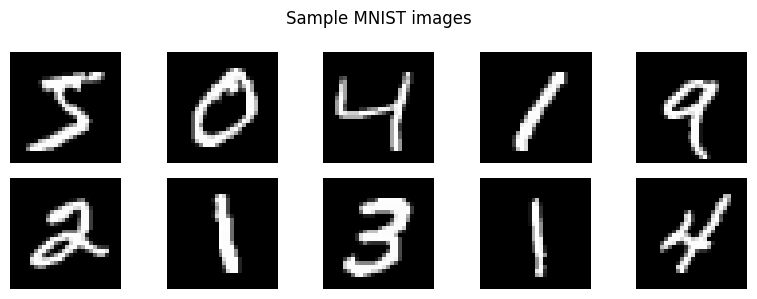

In [ ]:
(x_train, _), (x_test, _) = keras.datasets.mnist.load_data()

print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)
print("Data type:", x_train.dtype)
print("Original pixel range:", x_train.min(), "to", x_train.max())

plt.figure(figsize=(8, 3))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.axis("off")
plt.suptitle("Sample MNIST images")
plt.tight_layout()
plt.show()

In [ ]:
# Normalize pixel values to [0, 1] and flatten 28x28 images into 784 features.
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train_flat = x_train.reshape(-1, 784)
x_test_flat = x_test.reshape(-1, 784)

print("Flattened training shape:", x_train_flat.shape)
print("Flattened testing shape:", x_test_flat.shape)
print("Normalized pixel range:", x_train_flat.min(), "to", x_train_flat.max())

Flattened training shape: (60000, 784)
Flattened testing shape: (10000, 784)
Normalized pixel range: 0.0 to 1.0


## Part B – Build the Encoder, bottleneck, Decoder, and Autoencoder

In [ ]:
input_dim = 784
latent_dim = 32

# Encoder
encoder_input = keras.Input(shape=(input_dim,), name="encoder_input")
x = layers.Dense(256, activation="relu")(encoder_input)
x = layers.Dense(128, activation="relu")(x)
latent = layers.Dense(latent_dim, activation="relu", name="bottleneck")(x)
encoder = keras.Model(encoder_input, latent, name="Encoder")

# Decoder
decoder_input = keras.Input(shape=(latent_dim,), name="decoder_input")
x = layers.Dense(128, activation="relu")(decoder_input)
x = layers.Dense(256, activation="relu")(x)
decoder_output = layers.Dense(input_dim, activation="sigmoid")(x)
decoder = keras.Model(decoder_input, decoder_output, name="Decoder")

# Complete Autoencoder
autoencoder_input = keras.Input(shape=(input_dim,), name="autoencoder_input")
encoded = encoder(autoencoder_input)
reconstructed = decoder(encoded)
autoencoder = keras.Model(autoencoder_input, reconstructed, name="Autoencoder")

autoencoder.compile(optimizer="adam", loss="mse")
encoder.summary()
decoder.summary()
autoencoder.summary()

Model: "Encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 32)             │         4,128 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 237,984 (929.62 KB)

 Trainable params: 237,984 (929.62 KB)

 Non-trainable params: 0 (0.00 B)

Model: "Decoder"

... (5 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ autoencoder_input (InputLayer)  │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Encoder (Functional)            │ (None, 32)             │       237,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Decoder (Functional)            │ (None, 784)            │       238,736 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 476,720 (1.82 MB)

 Trainable params: 476,720 (1.82 MB)

 Non-trainable params: 0 (0.00 B)

## Part C – Train and evaluate the Autoencoder

In [ ]:
EPOCHS = 10
BATCH_SIZE = 256

history = autoencoder.fit(
    x_train_flat,
    x_train_flat,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    validation_data=(x_test_flat, x_test_flat),
    verbose=1
)

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - loss: 0.0560 - val_loss: 0.0303
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - loss: 0.0249 - val_loss: 0.0210
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 11s 48ms/step - loss: 0.0189 - val_loss: 0.0166
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 23ms/step - loss: 0.0159 - val_loss: 0.0144
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 31ms/step - loss: 0.0141 - val_loss: 0.0130
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - loss: 0.0129 - val_loss: 0.0120
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 32ms/step - loss: 0.0120 - val_loss: 0.0113
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 23ms/step - loss: 0.0113 - val_loss: 0.0107
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 29ms/step - loss: 0.0107 - val_loss: 0.0102
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - loss: 0.0102 - val_loss: 0.0098


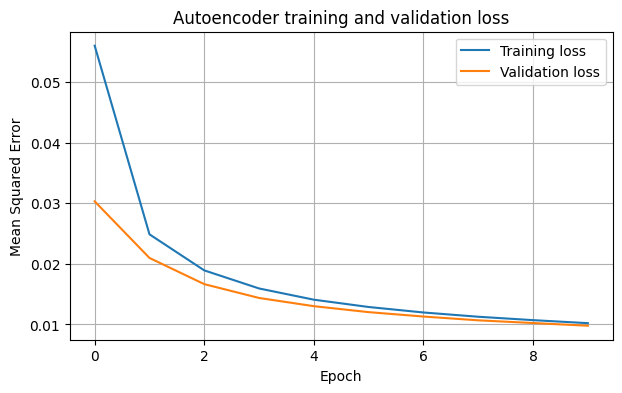

Test reconstruction MSE: 0.009785


In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Autoencoder training and validation loss")
plt.legend()
plt.grid(True)
plt.show()

test_mse = autoencoder.evaluate(x_test_flat, x_test_flat, verbose=0)
print(f"Test reconstruction MSE: {test_mse:.6f}")

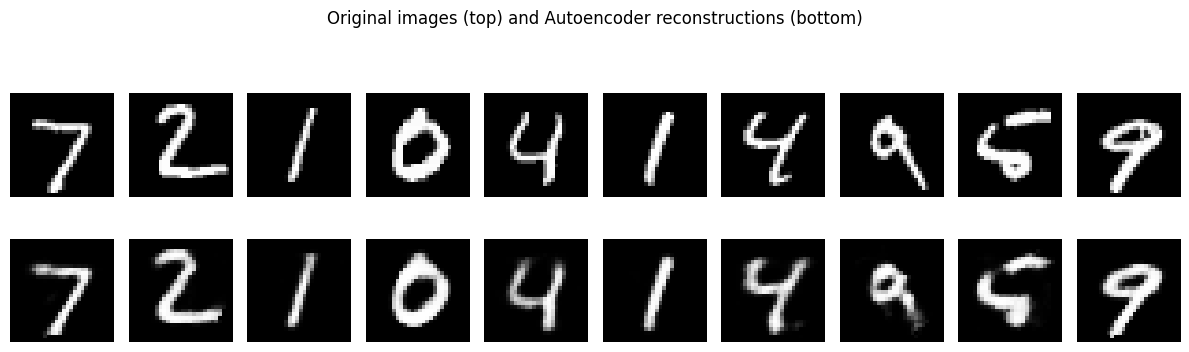

In [ ]:
# Compare original and reconstructed test images.
reconstructed_flat = autoencoder.predict(x_test_flat[:10], verbose=0)
reconstructed_images = reconstructed_flat.reshape(-1, 28, 28)

plt.figure(figsize=(12, 4))
for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i], cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.ylabel("Original")

    plt.subplot(2, 10, 10 + i + 1)
    plt.imshow(reconstructed_images[i], cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.ylabel("Reconstructed")
plt.suptitle("Original images (top) and Autoencoder reconstructions (bottom)")
plt.tight_layout()
plt.show()

## Part D – Dimensionality reduction and latent-feature visualization

In [ ]:
# Extract compact latent representations using the trained Encoder.
latent_train = encoder.predict(x_train_flat[:5000], verbose=0)
latent_test = encoder.predict(x_test_flat, verbose=0)

print("Original feature dimension:", x_test_flat.shape[1])
print("Compressed feature dimension:", latent_test.shape[1])
print("Latent training shape:", latent_train.shape)
print("Latent testing shape:", latent_test.shape)

Original feature dimension: 784
Compressed feature dimension: 32
Latent training shape: (5000, 32)
Latent testing shape: (10000, 32)


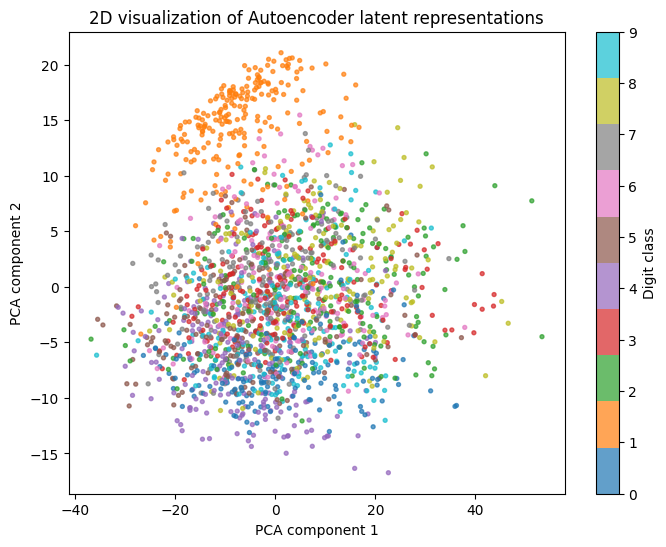

In [ ]:
# Visualize a two-dimensional projection of latent features using PCA.
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=SEED)
latent_2d = pca.fit_transform(latent_test[:2000])

# Load labels separately for visualization only.
(_, y_train_unused), (_, y_test) = keras.datasets.mnist.load_data()

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    latent_2d[:, 0], latent_2d[:, 1],
    c=y_test[:2000], cmap="tab10", s=8, alpha=0.7
)
plt.xlabel("PCA component 1")
plt.ylabel("PCA component 2")
plt.title("2D visualization of Autoencoder latent representations")
plt.colorbar(scatter, label="Digit class")
plt.show()

Selected input shape: (8, 784)
Selected latent shape: (8, 32)
Reconstructed shape: (8, 784)


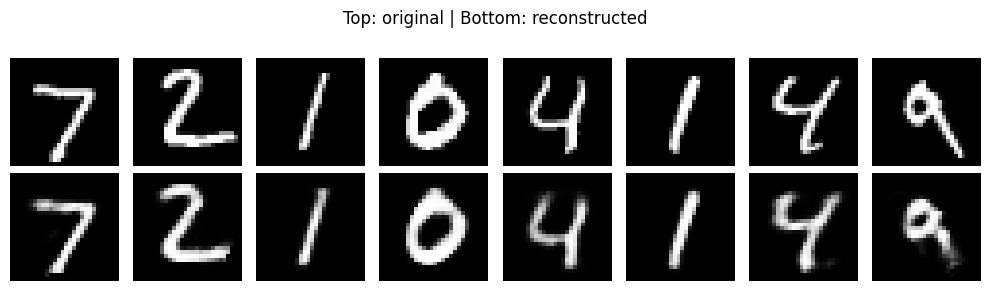

In [ ]:
# Reconstruct selected test samples through Encoder followed by Decoder.
selected = x_test_flat[:8]
selected_latent = encoder.predict(selected, verbose=0)
selected_reconstructions = decoder.predict(selected_latent, verbose=0)

print("Selected input shape:", selected.shape)
print("Selected latent shape:", selected_latent.shape)
print("Reconstructed shape:", selected_reconstructions.shape)

plt.figure(figsize=(10, 3))
for i in range(8):
    plt.subplot(2, 8, i + 1)
    plt.imshow(selected[i].reshape(28, 28), cmap="gray")
    plt.axis("off")
    plt.subplot(2, 8, 8 + i + 1)
    plt.imshow(selected_reconstructions[i].reshape(28, 28), cmap="gray")
    plt.axis("off")
plt.suptitle("Top: original | Bottom: reconstructed")
plt.tight_layout()
plt.show()



## Conclusion

A Dense Autoencoder was implemented and trained on MNIST. The Encoder learned lower-dimensional representations, and the Decoder reconstructed images from those representations. Reconstruction loss and visual comparisons were used to evaluate performance.

